In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np
import re
import gspread
import json
import os
import requests
from gspread_dataframe import get_as_dataframe, set_with_dataframe
from google.oauth2 import service_account # based on google-auth library
from pathlib import Path


In [2]:
file_data = json.load(open(os.path.expanduser("../../../ServiceAccountsKey.json")))
# (2) transform the content into crendentials object
credentials = service_account.Credentials.from_service_account_info(file_data)
# (3) specify your usage of the credentials
scoped_credentials = credentials.with_scopes(
    ['https://spreadsheets.google.com/feeds', 'https://www.googleapis.com/auth/drive'])
# (4) use the constrained credentials for authentication of gspread package
gc = gspread.Client(auth=scoped_credentials)

ruland_gs = gc.open_by_url(
    "https://docs.google.com/spreadsheets/d/1od248fJpNbwMO8IVZQVO3xnzrmmTe68yS9XWajyuk5o/edit?usp=sharing")

In [3]:
lexeme_df = pd.read_parquet("../data/large_files/ruland-emlap-grela.parquet")

In [52]:
lexeme_df.head(5)

,Lemma,lemmas_all,target_canonical,entry_ids,entry_count,types,variants,notes,senses_flat,sense_count,...,emlap_instances_freq,noscemus_alchymia_instances_freq,noscemus_rest_instances_freq,cc_instances_freq,grela_la_instances_freq,emlap_vs_grela_la_rel_freq,p_emb_emlap_vs_noscemus_alchymy,p_emb_emlap_vs_noscemus_rest,p_emb_emlap_vs_cc,ruland_instances_ids
0,Naphtha,[Naphtha],naphtha,[Ruland1612-Naphtha],1,[N],[],[],"[{'def': 'id est, pir, ignis.; id est, flatus ...",15,...,0.000003,0.000002,0.000003,1.884046e-07,0.000001,2.527169,0.0323,0.4032,0.0,"[100012, 100012, 100012, 100038, 100063, 10007..."
1,Baurac,"[Baurac, Bäurac]",baurac,"[Ruland1612-Baurac, Ruland1612-Baurac, Ruland1...",10,[B],[],[],"[{'def': None, 'entry_id': 'Ruland1612-Baurac'...",10,...,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.0000,0.0000,0.0,"[100004, 100004]"
2,Nitrum,[Nitrum],nitrum,"[None, Ruland1612-Nitrum, Ruland1612-Nitrum, R...",9,[N],[],[],"[{'def': 'Baurach, sal petrosum, nitrum à Germ...",9,...,0.000112,0.000129,0.000046,5.381306e-06,0.000024,4.692429,0.2287,0.4163,0.0,"[100001, 100002, 100002, 100004, 100004, 10000..."
3,Elixir,[Elixir],elixir,"[Ruland1612-Elixir,-Elei,, Ruland1612-Elixir, ...",6,[E],"[Elei, Xir]",[],"[{'def': 'id est, Medicina.', 'entry_id': 'Rul...",5,...,0.000225,0.000034,0.000003,2.904570e-07,0.000006,38.543132,0.6775,0.0088,0.0,"[100001, 100004, 100004, 100004, 100004, 10000..."
4,Magnesia,[Magnesia],magnesia,"[Ruland1612-Magnesia, Ruland1612-Magnesia, Rul...",5,[M],[],[],"[{'def': 'id est, testudo vel sulphul.', 'entr...",5,...,0.000050,0.000050,0.000003,5.141875e-07,0.000004,13.463704,0.0386,0.2760,0.0,"[100003, 100003, 100003, 100003, 100004, 10000..."


In [4]:
len(lexeme_df)

2846

In [5]:
lexeme_df.columns

Index(['Lemma', 'lemmas_all', 'target_canonical', 'entry_ids', 'entry_count',
       'types', 'variants', 'notes', 'senses_flat', 'sense_count',
       'sense_def_all', 'sense_def_strict_all', 'sense_raw_all',
       'translations_all', 'target_len', 'target_relemmatized',
       'instance_fname', 'emlap_instances_N', 'noscemus_alchymia_instances_N',
       'noscemus_rest_instances_N', 'cc_instances_N', 'grela_la_instances_N',
       'emlap_instances_freq', 'noscemus_alchymia_instances_freq',
       'noscemus_rest_instances_freq', 'cc_instances_freq',
       'grela_la_instances_freq', 'emlap_vs_grela_la_rel_freq',
       'p_emb_emlap_vs_noscemus_alchymy', 'p_emb_emlap_vs_noscemus_rest',
       'p_emb_emlap_vs_cc'],
      dtype='object')

In [6]:
lexeme_df.loc[1780]

Lemma                                                                           Macha
lemmas_all                                                                    [Macha]
target_canonical                                                                macha
entry_ids                                                          [Ruland1612-MAcha]
entry_count                                                                         1
types                                                                             [M]
variants                                                                           []
notes                                                                              []
senses_flat                         [{'def': 'id est, vermiculus volans', 'entry_i...
sense_count                                                                         1
sense_def_all                                             [id est, vermiculus volans]
sense_def_strict_all                                  

In [53]:
emlap_metadata = pd.read_csv(
        "https://raw.githubusercontent.com/CCS-ZCU/EMLAP_ETL/refs/heads/master/data/emlap_metadata.csv",
        sep=";",
    )
emlap_metadata.head(5)

,Unnamed: 0.1,Unnamed: 0,working_title,filenames,no.,is_done,is_noscemus,if_noscemus_id,AUTHORSHIP,is_one_author,...,CONTENTS,genre,subject,SOURCE OF FILE,link,source_of_file,origin_of_copy,other_notes,tokens_N,aurhor_wd
0,0,0,"Augurello, Chrysopoeia",100001_Augurello1515_Chrysopoeia_GB_Noscemus,100001,True,True,713324.0,NaN,True,...,NaN,didactic poem,alchemy,NaN,https://wiki.uibk.ac.at/noscemus/Chrysopoeia,GB,Noscemus,NaN,23225,NaN
1,1,1,"Pseudo-Lull, Secretis",100002_Pseudo-Lull1518_De secretis_naturae_MDZ...,100002,True,False,NaN,NaN,True,...,NaN,treatise,"alchemy, medicine",NaN,https://www.digitale-sammlungen.de/en/view/bsb...,MDZ,MBS,NaN,24696,NaN
2,2,2,"Pantheus, Ars Transmutatione",100003_Pantheus1518_Ars_Transmutationis_Metall...,100003,True,False,NaN,NaN,True,...,NaN,treatise,alchemy,NaN,https://www.google.co.uk/books/edition/Ars_Tra...,GB,BL,NaN,8683,NaN
3,3,3,"Anon, Vera alchemiae",100004_Anon1561_Verae_Alchemiae_MDZ_MBS,100004,True,False,NaN,NaN,True,...,NaN,"compendium, florilegium",alchemy,NaN,https://mdz-nbn-resolving.de/details:bsb10141168,MDZ,MBS,NaN,368660,NaN
4,4,4,"Pantheus, Voarchadumia",100005_Pantheus1530_Voarchadumia_ONB,100005,True,False,NaN,NaN,True,...,NaN,treatise,alchemy,NaN,https://data.onb.ac.at/rep/10588E49,ONB,ONB,NaN,21175,NaN


In [54]:
def get_short_label(row):
    author_title = row['working_title'].split(", ")
    author = author_title[0]
    title = author_title[1]
    short_title = " ".join(title.split()[:2]) + "..."
    author_title_short = ", ".join([author, short_title])
    short_label = f"{author_title_short} ({row['date_publication']})"
    return short_label

emlap_metadata["labeldate"] = emlap_metadata.apply(
        lambda row: get_short_label(row),
        axis=1,
    )

In [55]:
emlap_metadata

,Unnamed: 0.1,Unnamed: 0,working_title,filenames,no.,is_done,is_noscemus,if_noscemus_id,AUTHORSHIP,is_one_author,...,genre,subject,SOURCE OF FILE,link,source_of_file,origin_of_copy,other_notes,tokens_N,aurhor_wd,labeldate
0,0,0,"Augurello, Chrysopoeia",100001_Augurello1515_Chrysopoeia_GB_Noscemus,100001,True,True,713324.0,NaN,True,...,didactic poem,alchemy,NaN,https://wiki.uibk.ac.at/noscemus/Chrysopoeia,GB,Noscemus,NaN,23225,NaN,"Augurello, Chrysopoeia... (1515)"
1,1,1,"Pseudo-Lull, Secretis",100002_Pseudo-Lull1518_De secretis_naturae_MDZ...,100002,True,False,NaN,NaN,True,...,treatise,"alchemy, medicine",NaN,https://www.digitale-sammlungen.de/en/view/bsb...,MDZ,MBS,NaN,24696,NaN,"Pseudo-Lull, Secretis... (1518)"
2,2,2,"Pantheus, Ars Transmutatione",100003_Pantheus1518_Ars_Transmutationis_Metall...,100003,True,False,NaN,NaN,True,...,treatise,alchemy,NaN,https://www.google.co.uk/books/edition/Ars_Tra...,GB,BL,NaN,8683,NaN,"Pantheus, Ars Transmutatione... (1518)"
3,3,3,"Anon, Vera alchemiae",100004_Anon1561_Verae_Alchemiae_MDZ_MBS,100004,True,False,NaN,NaN,True,...,"compendium, florilegium",alchemy,NaN,https://mdz-nbn-resolving.de/details:bsb10141168,MDZ,MBS,NaN,368660,NaN,"Anon, Vera alchemiae... (1561)"
4,4,4,"Pantheus, Voarchadumia",100005_Pantheus1530_Voarchadumia_ONB,100005,True,False,NaN,NaN,True,...,treatise,alchemy,NaN,https://data.onb.ac.at/rep/10588E49,ONB,ONB,NaN,21175,NaN,"Pantheus, Voarchadumia... (1530)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,95,95,"Agricola, Galerazeya",100096_Agricola1631_Galerazeya_GB_BL,100096,True,False,NaN,NaN,True,...,treatise,"alchemy, religion",NaN,https://www.google.co.uk/books/edition/Galeraz...,GB,BL,NaN,36816,NaN,"Agricola, Galerazeya... (1631)"
96,96,96,"Van Helmont, Opuscula",100097_Van_Helmont1644_Opuscula_medica_MDZ_MBS,100097,True,False,NaN,NaN,True,...,treatise,"alchemy, medicine",NaN,http://mdz-nbn-resolving.de/urn:nbn:de:bvb:12-...,MDZ,MBS,NaN,204957,NaN,"Van Helmont, Opuscula... (1644)"
97,97,97,"Burggravius, Biolychnium",100098_Burggravius1630_Biolychnium_VD17_SLUB,100098,True,False,NaN,NaN,False,...,treatise,"alchemy, medicine",NaN,http://digital.slub-dresden.de/id475732545,VD17,SLUB,NaN,31139,NaN,"Burggravius, Biolychnium... (1630)"
98,98,98,"Francus, De arte chemica",100099_Francus1607_De Arte_Chemica_VD17_Halle,100099,True,False,NaN,NaN,True,...,treatise,"alchemy, Paracelsianism",NaN,https://opendata2.uni-halle.de//handle/1516514...,VD17,Halle,NaN,4512,NaN,"Francus, De arte... (1607)"


In [56]:
noscemus_emlap_ids = [str(int(x)) for x in emlap_metadata["if_noscemus_id"].unique() if pd.notna(x)]
noscemus_emlap_ids

['713324', '26765', '597737', '971293', '688159']

In [57]:
emlap_metadata["tokens_N"].sum()

np.int64(6477016)

In [58]:
# to work excusively with works from the older period
#emlap_metadata = emlap_metadata[emlap_metadata["date_publication"]<=1600]

In [59]:
emlap_metadata.columns

Index(['Unnamed: 0.1', 'Unnamed: 0', 'working_title', 'filenames', 'no.',
       'is_done', 'is_noscemus', 'if_noscemus_id', 'AUTHORSHIP',
       'is_one_author',
       '#if more than 1 author skip section and choose compendium below',
       'is_author_known', 'author_name', 'author_name_alternatives',
       'author_viaf', 'author_cerl', 'author_comments', 'is_compendium',
       'if_compendium', 'TRANSLATION / EDITORSHIP', 'is_translator',
       'translator_name', 'translator_name_alternatives',
       'translator_comments', 'is_editor', 'editor_name',
       'editor_name_alternatives', 'editor_comments', 'DATE OF PUBLICATION',
       'date_publication', 'date_certainty', 'date_not_after',
       'date_not_before', 'date_comment', 'TITLE', 'title_short', 'title_full',
       'title_viaf', 'title_comments', 'PLACE OF PUBLICATION',
       'place_publication', 'place_geonames', 'place_comments', 'PUBLISHER',
       'publisher_name', 'publisher_name_alternatives', 'publisher_comments'

In [60]:
emlap_metadata["labeldate"] = emlap_metadata.apply(lambda row: row["working_title"] + " ({})".format(str(row["date_publication"])), axis=1)

In [61]:
emlap_metadata.sort_values("date_publication", ascending=True, inplace=True)

## Exploring individual entries

In [62]:
# emlap_id_label_dict = dict(zip(emlap_metadata["No."], emlap_metadata["labeldate"]))

In [63]:
outdir = Path("../data/large_files/emlap_ruland_instances/")

def read_hits(fname):
    try:
        path = os.path.join(outdir, fname)
        instances = pd.read_parquet(path).to_dict("records")
    except:
        instances = []
    return instances


#df = pd.DataFrame(

emlap_instances = read_hits("mercurius_metallorum.parquet")

In [64]:
def extract_emlap_ids(fname):
    emlap_instances = read_hits(fname)
    return [instance["grela_id"][6:] for instance in emlap_instances if "emlap" in instance["grela_id"]]

lexeme_df["emlap_instances_ids"] = lexeme_df["instance_fname"].apply(extract_emlap_ids)

In [85]:
lexeme_df["grela_instances_N"] = lexeme_df["instance_fname"].apply(lambda fname: len(read_hits(fname)))

In [ ]:
#lexeme_df.to_parquet("../data/large_files/ruland-emlap-grela.parquet")

In [65]:
def make_plot_bar(entry):
    # Get instance IDs for the entry
    instances_ids = lexeme_df[lexeme_df["Lemma"] == entry]["emlap_instances_ids"].tolist()[0]
    counter = Counter(instances_ids)

    # Extract the keys (labels) and their corresponding counts (frequencies)
    emlap_metadata_instances = emlap_metadata.copy()
    emlap_metadata_instances["Frequency"] = (
        emlap_metadata_instances["no."].astype(str).map(counter).fillna(0).astype(int)
    )

    # Add bidecade labels to the DataFrame
    def get_bidecade_label(year):
        if not np.isnan(year):  # Handle NaN years safely
            start = (year // 20) * 20  # Determine the starting year of the bidecade
            end = start + 19  # Determine the ending year of the bidecade
            return f"{start}-{end}"
        return None

    emlap_metadata_instances["Bidecade"] = emlap_metadata_instances["date_publication"].apply(get_bidecade_label)

    # Group by Bidecade and sum frequencies and tokens_N
    emlap_instances_grouped = (
        emlap_metadata_instances.groupby("Bidecade", dropna=True)[["Frequency", "tokens_N"]]
        .sum()
        .reset_index()
    )

    # Sort bidecade intervals numerically
    emlap_instances_grouped = emlap_instances_grouped.sort_values(
        by="Bidecade",
        key=lambda col: col.str.extract(r"(\d+)")[0].astype(int)
    )

    # Calculate relative frequency (Frequency / tokens_N)
    emlap_instances_grouped["RelativeFrequency"] = (
        emlap_instances_grouped["Frequency"] / emlap_instances_grouped["tokens_N"]
    )

    # Calculate relative frequency for individual works
    emlap_metadata_instances["RelativeFrequency"] = (
        emlap_metadata_instances["Frequency"] / emlap_metadata_instances["tokens_N"]
    )

    # Create the 4 subplots (2x2 layout)
    fig, axes = plt.subplots(4, 1, figsize=(15, 30), dpi=300)

    # Plot 1: Absolute frequency vs. bidecades
    ax1 = axes[0]
    ax1.bar(
        emlap_instances_grouped["Bidecade"],
        emlap_instances_grouped["Frequency"],
        color="blue"
    )
    ax1.set_xlabel("Bidecades", fontsize=12)
    ax1.set_ylabel("Absolute Frequency", fontsize=12)
    ax1.set_title(f"Absolute Frequency of '{entry}' by Bidecades", fontsize=14)
    ax1.set_xticks(range(len(emlap_instances_grouped["Bidecade"])))
    ax1.set_xticklabels(emlap_instances_grouped["Bidecade"], rotation=90)

    # Plot 2: Relative frequency vs. bidecades
    ax2 = axes[1]
    ax2.bar(
        emlap_instances_grouped["Bidecade"],
        emlap_instances_grouped["RelativeFrequency"],
        color="orange"
    )
    ax2.set_xlabel("Bidecades", fontsize=12)
    ax2.set_ylabel("Relative Frequency (Frequency / tokens_N)", fontsize=12)
    ax2.set_title(f"Relative Frequency of '{entry}' by Bidecades", fontsize=14)
    ax2.set_xticks(range(len(emlap_instances_grouped["Bidecade"])))
    ax2.set_xticklabels(emlap_instances_grouped["Bidecade"], rotation=90)

    # Plot 3: Absolute frequency vs. works
    ax3 = axes[2]
    ax3.bar(
        emlap_metadata_instances["labeldate"],
        emlap_metadata_instances["Frequency"],
        color="blue"
    )
    ax3.set_xlabel("Works", fontsize=12)
    ax3.set_ylabel("Absolute Frequency", fontsize=12)
    ax3.set_title(f"Absolute Frequency of '{entry}' by Works", fontsize=14)
    ax3.set_xticks(range(len(emlap_metadata_instances["labeldate"])))
    ax3.set_xticklabels(emlap_metadata_instances["labeldate"], rotation=90, fontsize=9)

    # Plot 4: Relative frequency vs. works
    ax4 = axes[3]
    ax4.bar(
        emlap_metadata_instances["labeldate"],
        emlap_metadata_instances["RelativeFrequency"],
        color="orange"
    )
    ax4.set_xlabel("Works", fontsize=12)
    ax4.set_ylabel("Relative Frequency (Frequency / tokens_N)", fontsize=12)
    ax4.set_title(f"Relative Frequency of '{entry}' by Works", fontsize=14)
    ax4.set_xticks(range(len(emlap_metadata_instances["labeldate"])))
    ax4.set_xticklabels(emlap_metadata_instances["labeldate"], rotation=90, fontsize=9)

    # Adjust layout and display the plots
    plt.tight_layout()
    #plt.show()
    return fig

In [66]:
def plot_emlap_fourpanel(entry: str, grouped, perwork):
    fig, axes = plt.subplots(2, 2, figsize=(30, 12), dpi=600)

    ax1 = axes[0, 0]
    ax1.bar(grouped["Bidecade"], grouped["Frequency"], color="darkblue")
    ax1.set_xlabel("Bidecades", fontsize=11)
    ax1.set_ylabel("Absolute Frequency", fontsize=11)
    ax1.set_title(f"(A) Absolute Frequency of '{entry}' by Bidecades", fontsize=13)
    ax1.set_xticks(range(len(grouped["Bidecade"])))
    ax1.set_xticklabels(grouped["Bidecade"], rotation=90, fontsize=9)

    ax2 = axes[0, 1]
    ax2.bar(grouped["Bidecade"], grouped["RelativeFrequency"], color="darkgreen")
    ax2.set_xlabel("Bidecades", fontsize=11)
    ax2.set_ylabel("Relative Frequency (Frequency / tokens_N)", fontsize=11)
    ax2.set_title(f"(B) Relative Frequency of '{entry}' by Bidecades", fontsize=13)
    ax2.set_xticks(range(len(grouped["Bidecade"])))
    ax2.set_xticklabels(grouped["Bidecade"], rotation=90, fontsize=9)

    ax3 = axes[1, 0]
    ax3.bar(perwork["labeldate"], perwork["Frequency"], color="darkblue")
    ax3.set_xlabel("Works", fontsize=11)
    ax3.set_ylabel("Absolute Frequency", fontsize=11)
    ax3.set_title(f"(C) Absolute Frequency of '{entry}' by Works", fontsize=13)
    ax3.set_xticks(range(len(perwork["labeldate"])))
    ax3.set_xticklabels(perwork["labeldate"], rotation=90, fontsize=8)

    ax4 = axes[1, 1]
    ax4.bar(perwork["labeldate"], perwork["RelativeFrequency"], color="darkgreen")
    ax4.set_xlabel("Works", fontsize=11)
    ax4.set_ylabel("(D) Relative Frequency (Frequency / tokens_N)", fontsize=11)
    ax4.set_title(f"Relative Frequency of '{entry}' by Works", fontsize=13)
    ax4.set_xticks(range(len(perwork["labeldate"])))
    ax4.set_xticklabels(perwork["labeldate"], rotation=90, fontsize=8)

    plt.tight_layout()
    return fig

In [67]:
entry = "Lapis philosophorum"
instances_ids = lexeme_df[lexeme_df["Lemma"] == entry]["emlap_instances_ids"].tolist()[0]
counter = Counter(instances_ids)
emlap_metadata_instances = emlap_metadata.copy()
emlap_metadata_instances["Frequency"] = (
        emlap_metadata_instances["no."].astype(str).map(counter).fillna(0).astype(int))

In [68]:
emlap_metadata_instances.head(5)

,Unnamed: 0.1,Unnamed: 0,working_title,filenames,no.,is_done,is_noscemus,if_noscemus_id,AUTHORSHIP,is_one_author,...,subject,SOURCE OF FILE,link,source_of_file,origin_of_copy,other_notes,tokens_N,aurhor_wd,labeldate,Frequency
0,0,0,"Augurello, Chrysopoeia",100001_Augurello1515_Chrysopoeia_GB_Noscemus,100001,True,True,713324.0,NaN,True,...,alchemy,NaN,https://wiki.uibk.ac.at/noscemus/Chrysopoeia,GB,Noscemus,NaN,23225,NaN,"Augurello, Chrysopoeia (1515)",0
1,1,1,"Pseudo-Lull, Secretis",100002_Pseudo-Lull1518_De secretis_naturae_MDZ...,100002,True,False,NaN,NaN,True,...,"alchemy, medicine",NaN,https://www.digitale-sammlungen.de/en/view/bsb...,MDZ,MBS,NaN,24696,NaN,"Pseudo-Lull, Secretis (1518)",4
2,2,2,"Pantheus, Ars Transmutatione",100003_Pantheus1518_Ars_Transmutationis_Metall...,100003,True,False,NaN,NaN,True,...,alchemy,NaN,https://www.google.co.uk/books/edition/Ars_Tra...,GB,BL,NaN,8683,NaN,"Pantheus, Ars Transmutatione (1518)",0
8,8,8,"Vegius, Inter inferiora corpora",100009_Vegius1518_Inter_inferiora_corpora_disp...,100009,True,False,NaN,NaN,False,...,Renaissance philosophy,NaN,http://data.onb.ac.at/rep/1099703B,ONB,ONB,NaN,27814,NaN,"Vegius, Inter inferiora corpora (1518)",0
12,12,12,"Ulstadt, Coelum",100013_Ulstad1525_Coelum_philosophorum_Medica_...,100013,True,False,NaN,NaN,True,...,"alchemy, quintessence",NaN,https://www.biusante.parisdescartes.fr/histmed...,Medica,BIUSP,NaN,41603,Q18026923,"Ulstadt, Coelum (1525)",7


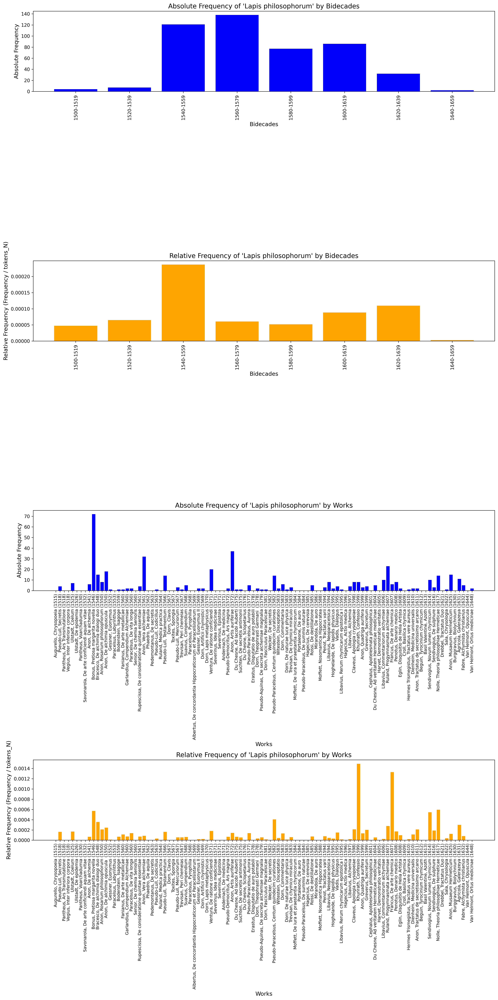

In [69]:
entry = "Lapis philosophorum"
fig = make_plot_bar(entry)

In [50]:
fig.savefig("../figures/casestudy_lapis_philosophorum.png", dpi=300)

## Overview

In [70]:
api_url = "https://ccs-lab.zcu.cz/grela-api/api/query"
query = "SELECT * FROM works"
works_df = pd.read_parquet(requests.post(api_url, json={"query": query}).json()["download_url"])

In [71]:
import json
import pandas as pd

def to_dict(x):
    if pd.isna(x):
        return {}
    if isinstance(x, dict):
        return x
    if isinstance(x, str):
        try:
            return json.loads(x)   # -> dict
        except json.JSONDecodeError:
            return {}
    return {}

works_df["noscemus_discipline"] = (
    works_df["subcorpus_specific_metadata"]
      .map(to_dict)
      .map(lambda d: d.get("noscemus_discipline"))
)

In [72]:
works_df[works_df["noscemus_discipline"].str.contains("Alchem", na=False)]

,grela_source,grela_id,author,title,not_before,not_after,date_random,provenience,place_publication,place_geonames,author_viaf,author_wd,author_gnd,title_viaf,subcorpus_specific_metadata,token_count,sentence_count,noscemus_discipline
9979,noscemus,noscemus_705665,"Achrelius, Daniel",Scientiarum magnes recitatus publice anno 1690...,1690,1690,1690,None,None,None,44659002,Q5541951,1055219730,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",8839,630,"Mathematics, Astronomy/Astrology/Cosmography, ..."
9991,noscemus,noscemus_658534,"Agricola, Georg","De re metallica libri XII, quibus officia, ins...",1556,1556,1556,None,None,None,None,None,118501062,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",221485,12233,"Meteorology/Earth sciences, Alchemy/Chemistry"
10005,noscemus,noscemus_863735,Anonymus 12,XVII. Discorso dei vantaggi della educazione f...,1785,1785,1785,None,None,None,None,None,None,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",49482,3633,Alchemy/Chemistry
10025,noscemus,noscemus_713324,"Augurello, Giovanni Aurelio",None,1515,1515,1515,None,None,None,None,None,None,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",26935,3626,Alchemy/Chemistry
10029,noscemus,noscemus_1031760,"Bacon, Francis","Pars secunda operis, quae dicitur Novum Organu...",1620,1620,1620,None,None,None,None,None,118505696,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",91341,6564,"Mathematics, Physics, Astronomy/Astrology/Cosm..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10870,noscemus,noscemus_695644,"Stattler, Benedikt",Mineralogiae et metallurgiae chemicae principi...,1765,1765,1765,None,None,None,None,None,118752839,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",47806,3219,"Meteorology/Earth sciences, Alchemy/Chemistry"
10871,noscemus,noscemus_695645,"Stattler, Benedikt",Mineralogiae et metallurgiae chemicae principi...,1765,1765,1765,None,None,None,None,None,118752839,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",62958,4129,"Meteorology/Earth sciences, Alchemy/Chemistry"
10878,noscemus,noscemus_668494,"Stromeyer, Friedrich",De gas hydrogenii arseniati natura atque indol...,1808,1808,1808,None,None,None,None,None,117345822,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",34164,1999,Alchemy/Chemistry
10887,noscemus,noscemus_604892,"Tazewell, William","Vade-mecum medicum in duas partes divisum, qua...",1798,1798,1798,None,None,None,None,None,None,None,"{""lagt_tlg_epithet"":null,""lagt_genre"":null,""no...",30497,5703,"Alchemy/Chemistry, Biology, Medicine"


In [73]:
works_df.groupby("grela_source").sum()["token_count"]

grela_source
cc          254770887
emlap         6477016
lagt         38223149
noscemus    137325383
vulgate        603091
Name: token_count, dtype: int64

In [74]:
corpora_token_counts_dict = works_df.groupby("grela_source").sum()["token_count"].to_dict()
corpora_token_counts_dict

{'cc': 254770887,
 'emlap': 6477016,
 'lagt': 38223149,
 'noscemus': 137325383,
 'vulgate': 603091}

In [75]:
corpora_token_counts_dict['grela'] = sum([corpora_token_counts_dict["cc"], corpora_token_counts_dict["noscemus"], corpora_token_counts_dict["emlap"]])

In [76]:
(corpora_token_counts_dict["emlap"] / corpora_token_counts_dict["cc"]) / 1

0.02542290477640014

In [77]:
1 / 0.025

40.0

In [78]:
corpora_token_counts_dict["emlap"] / corpora_token_counts_dict["noscemus"]


0.04716546830967149

In [79]:
1 / 0.119

8.403361344537815

In [80]:
lexeme_df["target_len"].value_counts()

target_len
1    1799
2     853
3     194
Name: count, dtype: int64

In [81]:
sum(lexeme_df["grela_instances_N"]>0)

KeyError: 'grela_instances_N'

In [82]:
sum(lexeme_df["grela_instances_N"]>0) / len(lexeme_df)


KeyError: 'grela_instances_N'

In [44]:
sum(lexeme_df["emlap_instances_N"]>0)

1457

In [45]:
lexeme_df["grela_instances_N"].sum()

np.int64(3419737)

In [46]:
lexeme_df["emlap_instances_N"].sum()

np.int64(288785)

In [15]:
lexeme_df.sort_values("emlap_instances_N", ascending=False)[:10]

,Lemma,lemmas_all,target_canonical,entry_ids,entry_count,types,variants,notes,senses_flat,sense_count,...,sense_def_strict_all,sense_raw_all,translations_all,target_len,target_relemmatized,instance_fname,noscemus_instances_N,cc_instances_N,emlap_instances_N,emlap_instances
596,Aurum,[Aurum],aurum,[Ruland1612-Aurum],1,[A],[],"[Natiuum purum, quod a natura tale est, cuius ...","[{'def': 'à Germanis', 'entry_id': 'Ruland1612...",1,...,[à Germanis],"[, à Germanis Goldtsa Chymistis dicitur Sol, &...","[{'entry_id': 'Ruland1612-Aurum', 'quote': 'Go...",1,aurum,aurum.parquet,9214,37216,11585,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
526,Argentum,[Argentum],argentum,"[Ruland1612-Argentum-à-Chymistis-Luna,-cui-eti...",1,[A],[Argentum],[],"[{'def': 'à Chymistis Luna, cui etiam tribuitu...",1,...,"[à Chymistis Luna, cui etiam tribuitur]","[à Chymistis Luna, cui etiam tribuitur: estque...",[{'entry_id': 'Ruland1612-Argentum-à-Chymistis...,1,argentum,argentum.parquet,7566,23030,10388,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
29,Oleum,[Oleum],oleum,"[Ruland1612-Oleum, Ruland1612-Oleum, Ruland161...",3,[O],[],[],"[{'def': 'id est, ignis, wirdt außgezogen von ...",3,...,"[id est, ignis, wirdt außgezogen von einer tro...","[id est, ignis, wirdt außgezogen von einer tro...","[{'entry_id': 'Ruland1612-Oleum', 'quote': 'wi...",1,oleum,oleum.parquet,12829,28096,10016,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
2277,Sal,[Sal],sal,[Ruland1612-Sal],1,[S],[],[],"[{'def': 'Alas Graece, Melech Arabice, vel sel...",1,...,"[Alas Graece, Melech Arabice, vel selenipum es...","[Alas Graece, Melech Arabice, vel selenipum es...","[{'entry_id': 'Ruland1612-Sal', 'quote': 'Salt...",1,sal,sal.parquet,12636,12520,9028,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
96,Metallum,[Metallum],metallum,"[Ruland1612-Metallum, Ruland1612-Metallum]",2,[M],[],[],"[{'def': 'vena, Ertz.', 'entry_id': 'Ruland161...",2,...,"[vena, Ertz., id est, conflatum argentum.]","[vena, Ertz., id est, conflatum argentum.]","[{'entry_id': 'Ruland1612-Metallum', 'quote': ...",1,metallum,metallum.parquet,7323,5847,9026,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
27,Mercurius,[Mercurius],mercurius,"[Ruland1612-Mercurius, Ruland1612-Mercurius, R...",3,[M],[],[],"[{'def': 'id est, sulphur.', 'entry_id': 'Rula...",3,...,"[id est, sulphur., est principium materiale, v...","[id est, sulphur. Mercurius. Mercurius ist in ...","[{'entry_id': 'Ruland1612-Mercurius', 'quote':...",1,mercurius,mercurius.parquet,8729,4942,7928,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ..."
10,Sulphur,[Sulphur],sulphur,"[Ruland1612-Sulphur, Ruland1612-Sulphur, Rulan...",4,[S],[],[],"[{'def': 'chibur, vel, Albusao Arabice dicitur...",4,...,"[chibur, vel, Albusao Arabice dicitur, pars la...","[chibur, vel, Albusao Arabice dicitur, pars la...","[{'entry_id': 'Ruland1612-Sulphur', 'quote': '...",1,sulphur,sulphur.parquet,4367,2719,6960,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
1200,Elementum,[Elementum],elementum,[Ruland1612-Elementum],1,[E],[],[],[{'def': 'quicquid ex matricibus elementorum p...,1,...,"[quicquid ex matricibus elementorum prouenit,]","[quicquid ex matricibus elementorum prouenit, ...","[{'entry_id': 'Ruland1612-Elementum', 'quote':...",1,elementum,elementum.parquet,9276,23583,6959,"[{'author': 'Augurelli, Giovanni Aurelio', 'en..."
18,Essentia,[Essentia],essentia,"[Ruland1612-Essentia, Ruland1612-Essentia, Rul...",3,[E],[],[],[{'def': 'est extractum simplex e reb. tota su...,3,...,[est extractum simplex e reb. tota sua natura ...,[est extractum simplex e reb. tota sua natura ...,[],1,essentia,essentia.parquet,5000,54270,5330,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ..."
197,Aer,[Aer],aer,[Ruland1612-Aer],1,[A],[],[],"[{'def': 'id est, aura, halitus, spiritus, ven...",1,...,"[id est, aura, halitus, spiritus, ventus,]","[id est, aura, halitus, spiritus, ventus, Wett...","[{'entry_id': 'Ruland1612-Aer', 'quote': 'Wett...",1,aer,aer.parquet,27774,43181,51

In [37]:
lexeme_df.columns

Index(['Lemma', 'lemmas_all', 'target_canonical', 'entry_ids', 'entry_count',
       'types', 'variants', 'notes', 'senses_flat', 'sense_count',
       'sense_def_all', 'sense_def_strict_all', 'sense_raw_all',
       'translations_all', 'target_len', 'target_relemmatized',
       'instance_fname', 'noscemus_instances_N', 'cc_instances_N',
       'emlap_instances_N', 'emlap_instances', 'grela_instances_N',
       'instances_ids'],
      dtype='object')

In [108]:
lexeme_df.head(5)

,Lemma,lemmas_all,target_canonical,entry_ids,entry_count,types,variants,notes,senses_flat,sense_count,...,noscemus_instances_N,cc_instances_N,emlap_instances_N,emlap_instances,grela_instances_N,instances_ids,emlap_rel_freq,noscemus_rel_freq,cc_rel_freq,grela_rel_freq
0,Naphtha,[Naphtha],naphtha,[Ruland1612-Naphtha],1,[N],[],[],"[{'def': 'id est, pir, ignis.; id est, flatus ...",15,...,243,48,20,"[{'author': 'Gessner, Conrad', 'end_sentence_i...",311,"[100012, 100012, 100012, 100038, 100063, 10007...",0.000003,0.000004,0.000000,0.000001
1,Baurac,"[Baurac, Bäurac]",baurac,"[Ruland1612-Baurac, Ruland1612-Baurac, Ruland1...",10,[B],[],[],"[{'def': None, 'entry_id': 'Ruland1612-Baurac'...",10,...,35,0,2,"[{'author': 'Gratarolo, Guilelmo', 'end_senten...",37,"[100004, 100004]",0.000000,0.000001,0.000000,0.000000
2,Nitrum,[Nitrum],nitrum,"[None, Ruland1612-Nitrum, Ruland1612-Nitrum, R...",9,[N],[],[],"[{'def': 'Baurach, sal petrosum, nitrum à Germ...",9,...,3205,1371,728,"[{'author': 'Augurelli, Giovanni Aurelio', 'en...",5304,"[100001, 100002, 100002, 100004, 100004, 10000...",0.000112,0.000059,0.000005,0.000017
3,Elixir,[Elixir],elixir,"[Ruland1612-Elixir,-Elei,, Ruland1612-Elixir, ...",6,[E],"[Elei, Xir]",[],"[{'def': 'id est, Medicina.', 'entry_id': 'Rul...",5,...,599,74,1455,"[{'author': 'Augurelli, Giovanni Aurelio', 'en...",2128,"[100001, 100004, 100004, 100004, 100004, 10000...",0.000225,0.000011,0.000000,0.000007
4,Magnesia,[Magnesia],magnesia,"[Ruland1612-Magnesia, Ruland1612-Magnesia, Rul...",5,[M],[],[],"[{'def': 'id est, testudo vel sulphul.', 'entr...",5,...,253,131,326,"[{'author': 'Panteo, Giovanni Agostino', 'end_...",710,"[100003, 100003, 100003, 100003, 100004, 10000...",0.000050,0.000005,0.000001,0.000002


In [106]:
top_10_emlap_instances_N = lexeme_df[['Lemma', 'target_canonical', 'target_relemmatized', 'emlap_instances_N', 'noscemus_instances_N', 'cc_instances_N','grela_instances_N']].sort_values("emlap_instances_N", ascending=False)[:10]

In [ ]:
set_with_dataframe(ruland_gs.add_worksheet("ruland_top10_2025-12-17", 1,1), top_10_emlap_instances_N)

In [ ]:
top_10_emlap_instances_N.to_csv("../data/lexeme_df_instances.csv")

In [118]:
# calculate relative frequency across corpora
for corp_label in ["emlap", "noscemus", "cc", "grela"]:
    corpus_token_count = corpora_token_counts_dict[corp_label]
    lexeme_df[f"{corp_label}_rel_freq"] = lexeme_df[f"{corp_label}_instances_N"] / corpus_token_count

In [120]:
# calculate relative frequency of terms weighted by their overall frequency in Latin part of Grela
lexeme_df["emlap_vs_grela_rel_freq"] = lexeme_df["emlap_rel_freq"] / lexeme_df["grela_rel_freq"]

In [124]:
top_20_emlap_vs_grela_rel_freq = lexeme_df[['Lemma', 'target_canonical', 'target_relemmatized', 'emlap_vs_grela_rel_freq', 'emlap_instances_N', 'noscemus_instances_N', 'cc_instances_N','grela_instances_N']].sort_values("emlap_vs_grela_rel_freq", ascending=False)[:20]
top_20_emlap_vs_grela_rel_freq

,Lemma,target_canonical,target_relemmatized,emlap_vs_grela_rel_freq,emlap_instances_N,noscemus_instances_N,cc_instances_N,grela_instances_N
762,Calcinatum maius,calcinatum maius,calcinatus magnus,48.755530,5,0,0,5
2476,Spagirus,spagirus,spagirus,46.588618,43,2,0,45
2475,Spagiria,spagiria,spagiria,46.317754,95,5,0,100
2829,Aeruginatio,aeruginatio,aeruginatio,46.189450,18,1,0,19
509,Archeus,archeus,archeus,45.797934,1022,64,2,1088
1583,Inhumatio,inhumatio,inhumatio,45.652906,103,6,1,110
46,Balneum Mariae,balneum mariae,balneum maria,45.179330,379,24,6,409
1169,Duelech,duelech,duelech,44.582760,203,19,0,222
2635,Thucia,thucia,thucia,44.323210,20,2,0,22
177,Adech,adech,adech,44.112147,19,2,0,21


In [125]:
set_with_dataframe(ruland_gs.add_worksheet("ruland_top20_emlap_vs_grela_rel_freq_2025-12-17", 1,1), top_20_emlap_vs_grela_rel_freq)

In [126]:
# explore multiword entries specifically

lexeme_df[lexeme_df["target_len"]>1].sort_values("emlap_instances_N", ascending=False)[:10]

,Lemma,lemmas_all,target_canonical,entry_ids,entry_count,types,variants,notes,senses_flat,sense_count,...,cc_instances_N,emlap_instances_N,emlap_instances,grela_instances_N,instances_ids,emlap_rel_freq,noscemus_rel_freq,cc_rel_freq,grela_rel_freq,emlap_vs_grela_rel_freq
33,Quinta essentia,[Quinta essentia],quinta essentia,"[Ruland1612-Quinta-essentia, Ruland1612-Quinta...",3,[Q],[],[],"[{'def': 'est natura vires, virtus color vita,...",3,...,86,1781,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ...",2383,"[100002, 100002, 100002, 100002, 100002, 10000...",0.000275,9.460521e-06,3.375582e-07,0.000008,36.438775
494,Aqua vitae,[Aqua vitae],aqua uitae,[Ruland1612-Aqua-vitae],1,[A],[],[],"[{'def': 'id est, Mercurius', 'entry_id': 'Rul...",1,...,195,922,"[{'author': 'Panteo, Giovanni Agostino', 'end_...",1311,"[100003, 100004, 100004, 100004, 100004, 10000...",0.000142,3.556863e-06,7.653936e-07,0.000004,34.288786
478,Aqua fortis,[Aqua fortis],aqua fortis,[Ruland1612-Aqua-fortis],1,[A],[],[],"[{'def': 'est, quae ex auibus, & corrosiuis ce...",1,...,62,684,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ...",1054,"[100002, 100004, 100004, 100004, 100004, 10000...",0.000106,5.646978e-06,2.433559e-07,0.000003,31.640211
2285,Sal armoniacus,[Sal armoniacus],sal armoniacus,[Ruland1612-Sal-armoniacus],1,[S],[],[],"[{'def': 'id est, sal saparicius, vel defossum...",1,...,9,483,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ...",695,"[100002, 100004, 100004, 100004, 100004, 10000...",0.000075,3.721872e-06,3.532586e-08,0.000002,33.883340
1698,Lapis philosophorum,[Lapis philosophorum],lapis philosophorum,[Ruland1612-Lapis-philosophorum],1,[L],[],[],"[{'def': 'sein die Haar der Menschen.', 'entry...",1,...,0,467,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ...",603,"[100002, 100002, 100002, 100002, 100004, 10000...",0.000072,2.493471e-06,0.000000e+00,0.000002,37.759258
602,Aurum potabile,[Aurum potabile],aurum potabile,[Ruland1612-Aurum-potabile],1,[A],[],[],"[{'def': 'est liquor, sine corrosiuo, quod pau...",1,...,5,405,"[{'author': 'Gratarolo, Guilelmo', 'end_senten...",482,"[100004, 100004, 100006, 100006, 100007, 10001...",0.000063,1.320073e-06,1.962548e-08,0.000002,40.966784
46,Balneum Mariae,[Balneum Mariae],balneum mariae,"[Ruland1612-Balneum-Mariae, Ruland1612-Balneum...",2,[B],[],[],"[{'def': 'id est, aqua calida.', 'entry_id': '...",2,...,6,379,"[{'author': 'Gratarolo, Guilelmo', 'end_senten...",409,"[100004, 100004, 100004, 100004, 100004, 10000...",0.000059,4.400243e-07,2.355057e-08,0.000001,45.179330
1845,Materia prima,[Materia prima],materia prima,[Ruland1612-Materia-prima],1,[M],[],[],"[{'def': '& huius vocabula,', 'entry_id': 'Rul...",1,...,1875,357,"[{'author': 'Pseudo-Lull', 'end_sentence_id': ...",2495,"[100002, 100002, 100004, 100004, 100004, 10000...",0.000055,4.821932e-06,7.359554e-06,0.000008,6.976242
789,Calor naturalis,[Calor naturalis],calor naturalis,[Ruland1612-Calor-naturalis],1,[C],[],[],"[{'def': 'est, quando radii solares, vel per s...",1,...,871,301,"[{'author': 'Panteo, Giovanni Agostino', 'end_...",1447,"[100003, 100004, 100004, 100004, 100004, 10000...",0.000046,5.041945e-06,3.418758e-06,0.000005,10.141959
2307,Sal petrae,[Sal petrae],sal petrae,[Ruland1612-Sal-petrae],1,[S],[],[],"[{'def': 'est, quod in testudinibus cellarum n...",1,...,10,291,"[{'author': 'Gratarolo, Guilelmo', 'end_senten...",381,"[100004, 100004, 100004, 100004, 100004, 10000...",0.000045,1.466748e-06,3.925095e-08,0.000001,37.238476


## Distributions of EMLAP works

In [127]:
lexeme_df["instances_counter"] = lexeme_df["emlap_instances_ids"].apply(Counter)

In [128]:
lexeme_df["instances_counter"].tolist()[:10]

[Counter({'100085': 14, '100012': 3, '100038': 1, '100063': 1, '100070': 1}),
 Counter({'100004': 2}),
 Counter({'100070': 102,
          '100034': 99,
          '100004': 46,
          '100072': 41,
          '100015': 39,
          '100075': 36,
          '100085': 36,
          '100044': 35,
          '100067': 34,
          '100076': 21,
          '100091': 18,
          '100032': 15,
          '100084': 14,
          '100038': 12,
          '100093': 12,
          '100012': 10,
          '100030': 9,
          '100069': 9,
          '100087': 9,
          '100081': 8,
          '100100': 8,
          '100005': 7,
          '100039': 7,
          '100043': 7,
          '100046': 7,
          '100011': 6,
          '100026': 6,
          '100049': 6,
          '100028': 5,
          '100097': 5,
          '100010': 4,
          '100013': 4,
          '100020': 4,
          '100016': 3,
          '100027': 3,
          '100073': 3,
          '100079': 3,
          '100098': 3,
      

In [129]:
distribution = sum(lexeme_df["instances_counter"], Counter())

In [130]:
distribution

Counter({'100004': 21381,
         '100085': 19893,
         '100070': 18155,
         '100072': 15367,
         '100100': 13915,
         '100038': 13671,
         '100067': 9225,
         '100032': 7573,
         '100015': 6759,
         '100075': 6751,
         '100016': 6731,
         '100097': 5953,
         '100065': 5278,
         '100012': 5242,
         '100011': 5187,
         '100028': 5075,
         '100084': 4514,
         '100022': 4447,
         '100074': 4443,
         '100044': 4186,
         '100094': 4075,
         '100071': 3783,
         '100069': 3330,
         '100091': 3163,
         '100059': 3129,
         '100010': 3123,
         '100076': 3061,
         '100049': 2924,
         '100030': 2680,
         '100063': 2569,
         '100013': 2451,
         '100040': 2402,
         '100045': 2402,
         '100007': 2290,
         '100087': 2241,
         '100034': 2240,
         '100064': 2238,
         '100046': 2211,
         '100020': 2130,
         '100056': 

In [160]:
df = emlap_metadata.copy()
df["Frequency"] = (
        df["no."].astype(str).map(distribution).fillna(0).astype(int)
    )
df["RelativeFrequency"] = df["Frequency"] / df["tokens_N"]

    # Sort by publication date for a chronological x-axis
# df = df.sort_values(["date_publication", "labeldate"], na_position="last")



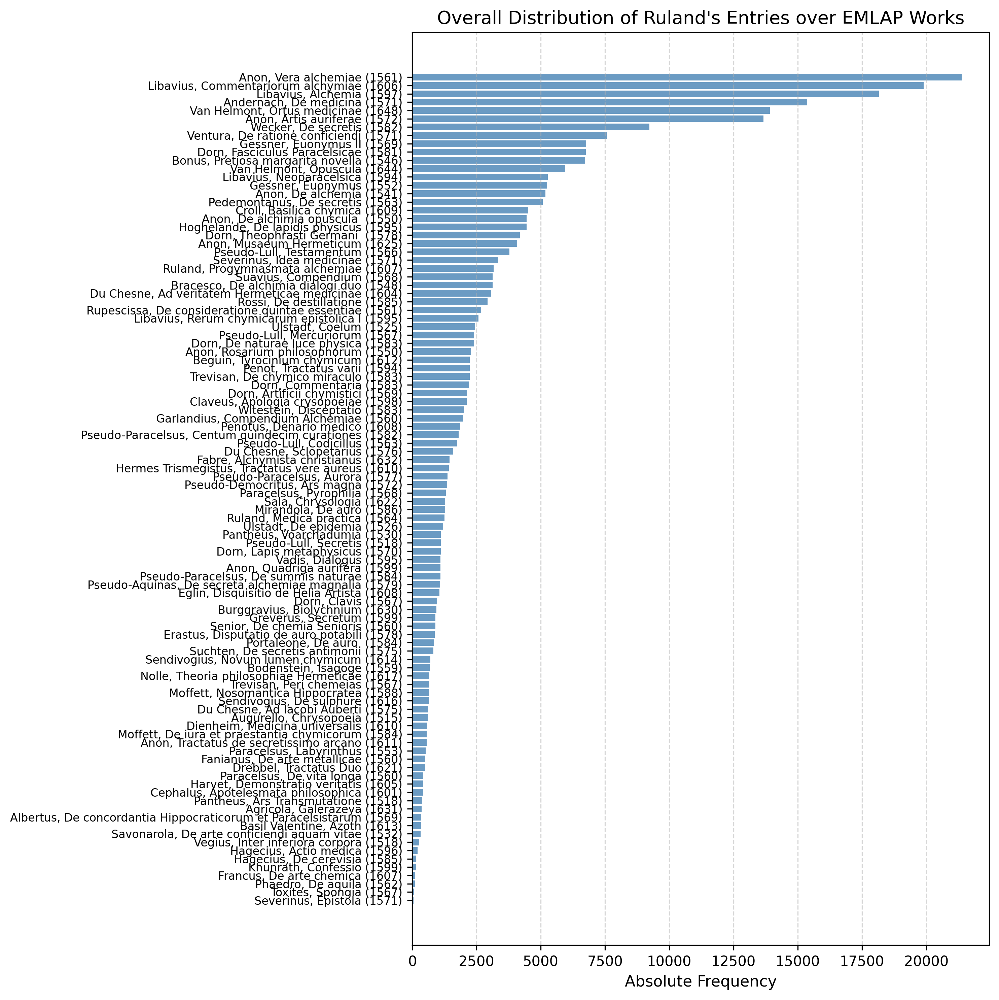

In [161]:
# Sort descending by Frequency
df = df.sort_values("Frequency", ascending=False)

# Prepare labels and positions
x_labels = df["labeldate"].tolist()
y_pos = np.arange(len(x_labels))

# Title
title = "Overall Distribution of Ruland's Entries over EMLAP Works"

# Create the figure
fig, ax = plt.subplots(figsize=(10, 10), dpi=300, tight_layout=True)

# Horizontal bar plot (sorted)
ax.barh(y_pos, df["Frequency"].to_numpy(), color="steelblue", alpha=0.8)

# Labeling
ax.set_yticks(y_pos)
ax.set_yticklabels(x_labels, fontsize=8)
ax.invert_yaxis()  # Highest at the top
ax.set_xlabel("Absolute Frequency", fontsize=11)
ax.set_title(title, fontsize=13)

# Add gridlines for readability
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [162]:
fig.savefig("../figures/ruland-emlap-overall-distribution-absolute.png", dpi=300)

In [163]:
df[-5:]["tokens_N"]

51    5358
98    4512
30    2489
13    2646
7     2261
Name: tokens_N, dtype: int64

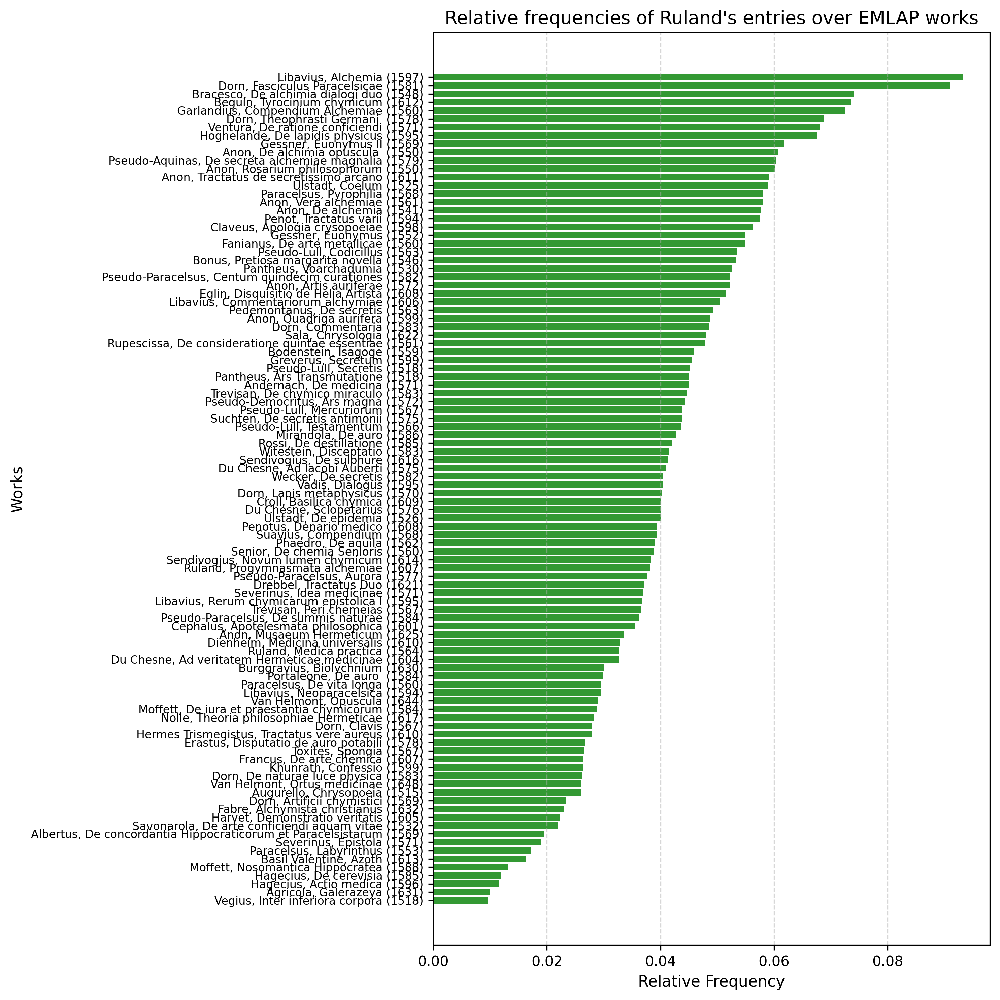

In [164]:
title = "Relative frequencies of Ruland's entries over EMLAP works"
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=300, tight_layout=True)

df = df.sort_values("RelativeFrequency", ascending=False)

x_labels = df["labeldate"].tolist()
y_pos


# Horizontal bar plot (sorted)
ax.barh(y_pos, df["RelativeFrequency"].to_numpy(), color="green", alpha=0.8)

# Labeling
ax.set_yticks(y_pos)
ax.set_ylabel("Works", fontsize=11)
ax.set_yticklabels(x_labels, fontsize=8)
ax.invert_yaxis()  # Highest at the top
ax.set_xlabel("Relative Frequency", fontsize=11)
ax.set_title(title, fontsize=13)

# Add gridlines for readability
ax.grid(axis="x", linestyle="--", alpha=0.5)


plt.tight_layout()
plt.show()

In [165]:
fig.savefig("../figures/ruland-emlap-overall-distribution-relative.png", dpi=300)

In [137]:
emlap_metadata["no."] = emlap_metadata["no."].astype(str)

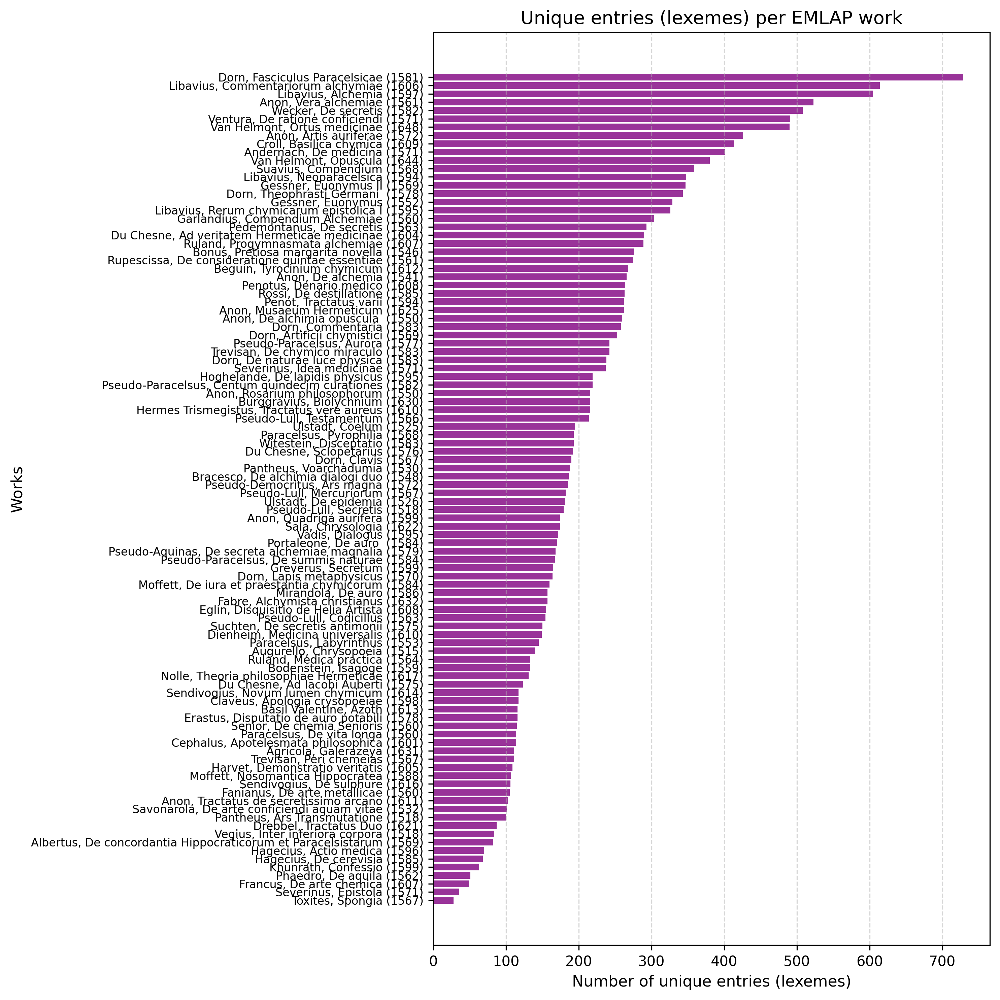

In [138]:
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) work_id → set of lexemes
work_to_lexemes = defaultdict(set)

# 2) Fill mapping from lexeme_df
for _, row in lexeme_df.iterrows():
    lemma = row["Lemma"]
    for work_id in row["emlap_instances_ids"]:
        work_to_lexemes[str(work_id)].add(lemma)

# 3) Counts DF
work_entry_counts = pd.DataFrame(
    [{"no.": w, "unique_entries": len(lemmas)} for w, lemmas in work_to_lexemes.items()]
)

# 4) Merge with metadata
work_entry_counts = emlap_metadata.merge(work_entry_counts, on="no.", how="left")
work_entry_counts["unique_entries"] = work_entry_counts["unique_entries"].fillna(0).astype(int)

# 5) Sort like your barh example (by value descending)
work_entry_counts = work_entry_counts.sort_values("unique_entries", ascending=False)

# 6) Plot barh
title = "Unique entries (lexemes) per EMLAP work"
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=300, tight_layout=True)

y_pos = np.arange(len(work_entry_counts))
x_labels = work_entry_counts["labeldate"].tolist()

ax.barh(y_pos, work_entry_counts["unique_entries"].to_numpy(), color="purple", alpha=0.8)

ax.set_yticks(y_pos)
ax.set_yticklabels(x_labels, fontsize=8)
ax.invert_yaxis()  # biggest on top

ax.set_xlabel("Number of unique entries (lexemes)", fontsize=11)
ax.set_ylabel("Works", fontsize=11)
ax.set_title(title, fontsize=13)

ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [139]:
fig.savefig("../figures/ruland-emlap-unique-entries.png", dpi=300)

In [142]:
df.head()

,grela_id,vocab_size
0,emlap_100001,4183
1,emlap_100002,3292
2,emlap_100003,1773
3,emlap_100004,13188
4,emlap_100005,3788


In [144]:
# get vocab size per EMLAP work
query = """
SELECT
  t.grela_id,
  COUNT(DISTINCT t.lemma) AS vocab_size
FROM tokens t
JOIN works w
  ON w.grela_id = t.grela_id
WHERE w.grela_source = 'emlap'
  AND t.lemma IS NOT NULL
  AND trim(t.lemma) <> ''
GROUP BY t.grela_id
ORDER BY t.grela_id
"""

resp = requests.post(api_url, json={"query": query}, timeout=120)
resp.raise_for_status()

download_url = resp.json()["download_url"]
df = pd.read_parquet(download_url)

# dict: {grela_id: vocab_size}
vocab_by_work = dict(zip(df["grela_id"], df["vocab_size"]))

print(len(vocab_by_work))
print(list(vocab_by_work.items())[:5])

100
[('emlap_100001', 4183), ('emlap_100002', 3292), ('emlap_100003', 1773), ('emlap_100004', 13188), ('emlap_100005', 3788)]


In [166]:
# add vocab size to work_entry_counts DF
work_entry_counts["vocab_size"] = work_entry_counts["no."].apply(lambda x: vocab_by_work["emlap_" + str(x)])

In [167]:
# check correlation between "tokens_N" and "vocab_size"
work_entry_counts[["tokens_N", "vocab_size"]].corr()

,tokens_N,vocab_size
tokens_N,1.000000,0.932232
vocab_size,0.932232,1.000000


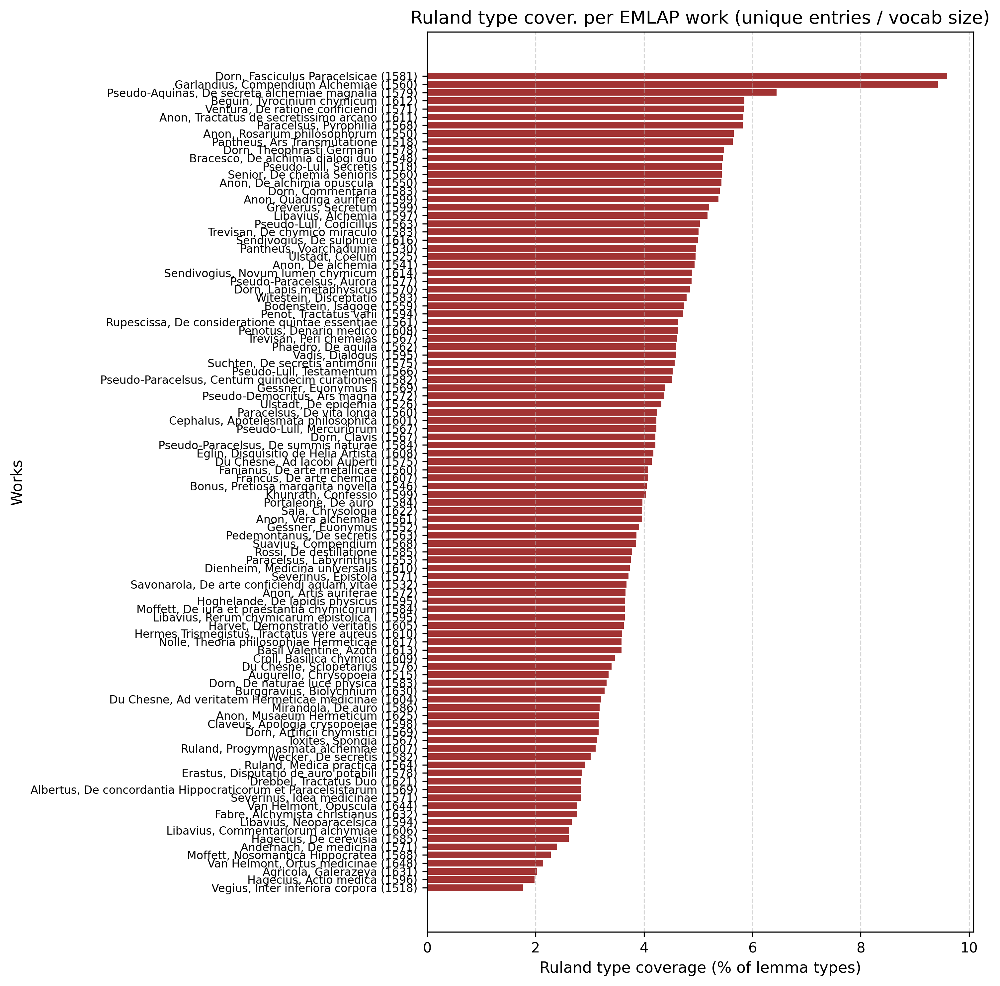

In [168]:
# 5) Compute type-normalized coverage (share of work vocab covered by Ruland entries)
work_entry_counts["ruland_type_share"] = np.where(
    work_entry_counts["vocab_size"] > 0,
    work_entry_counts["unique_entries"] / work_entry_counts["vocab_size"],
    0.0
)

# Optional: express as percent for plotting
work_entry_counts["ruland_type_share_pct"] = 100 * work_entry_counts["ruland_type_share"]

# 6) Sort by share descending (like your previous plot)
work_entry_counts = work_entry_counts.sort_values("ruland_type_share_pct", ascending=False)

# 7) Plot barh
title = "Ruland type cover. per EMLAP work (unique entries / vocab size)"
fig, ax = plt.subplots(1, 1, figsize=(10, 10), dpi=300, tight_layout=True)

y_pos = np.arange(len(work_entry_counts))
y_labels = work_entry_counts["labeldate"].tolist()

ax.barh(
    y_pos,
    work_entry_counts["ruland_type_share_pct"].to_numpy(),
    color="darkred",
    alpha=0.8
)

ax.set_yticks(y_pos)
ax.set_yticklabels(y_labels, fontsize=8)
ax.invert_yaxis()  # biggest on top

ax.set_xlabel("Ruland type coverage (% of lemma types)", fontsize=11)
ax.set_ylabel("Works", fontsize=11)
ax.set_title(title, fontsize=13)

ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()

In [169]:
fig.savefig("../figures/ruland-emlap-unique-entries-vocab-share.png", dpi=300)